# Chapitre 11 - Exercices 11.7 à 11.11

Ce notebook traite les exercices suivants du chapitre 11, centrés sur l'event sourcing
et le traitement des flux :

- **11.7** : un compte bancaire en event sourcing, concurrence et instantanés (mini-lab) ;
- **11.8** : fenêtres à la main (calcul) ;
- **11.9** : choisir la marge d'un filigrane (calcul et simulation) ;
- **11.10** : jointure recherches-clics, fenêtre et taille de l'état (calcul et
  simulation) ;
- **11.11** : idempotence, déterminisme et fencing (mini-lab).

In [1]:
import math
import sqlite3
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import streams as st
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
Z = NormalDist()

## Exercice 11.7 : un compte bancaire en event sourcing

**Énoncé.** Un compte reçoit deux commandes : `deposer(montant)` et `retirer(montant)`,
cette dernière étant refusée si le solde est insuffisant. Les événements sont `Depose` et
`Retire`.

1. Écrire `appliquer(etat, evt)` et `decider(etat, commande)`.
2. Deux distributeurs traitent en même temps un retrait de 70 € sur un compte de 100 € :
   chacun lit le flux, décide, puis ajoute son événement. Montrer qu'un ajout **sans**
   contrôle de version peut mettre le compte à découvert, et qu'un ajout avec la version
   attendue (`expected_version`) ne le peut pas. Mesurer sur 1 000 entrelacements
   aléatoires.
3. Un compte actif accumule 2 millions d'événements en dix ans. On veut charger son
   état en rejouant au plus 500 événements. Quelle politique d'instantanés ? Combien
   d'instantanés stocke-t-on si l'on ne garde que le dernier, ou tous ?
4. Le service marketing veut un relevé mensuel des dépôts. Comment l'obtenir sans
   toucher au code existant ?

**Rappels.** Commandes et événements, rejeu, instantanés, contrôle de concurrence
optimiste, nouvelles vues par rejeu (cours 4, sections 2, 4 et 5, sections
*Event Sourcing*, *Deriving several views from the same event log* et *Concurrency
control*).

**Solution.**

*1.* Le code ci-dessous. `decider` ne modifie rien : il valide la commande contre l'état
courant et renvoie les événements à ajouter (aucun si elle est refusée).

In [2]:
def appliquer(solde, e):
    solde = solde or 0
    return solde + e.data["montant"] if e.type == "Depose" else solde - e.data["montant"]

def decider(solde, commande):
    typ, montant = commande
    solde = solde or 0
    if typ == "deposer":
        return [("Depose", {"montant": montant})]
    return [("Retire", {"montant": montant})] if solde >= montant else []

def course(controle, seed):
    """Deux distributeurs lisent, décident et ajoutent, dans un ordre aléatoire
    (chaque distributeur lit avant d'ajouter)."""
    r = np.random.default_rng(seed)
    es = st.EventStore()
    es.append("compte", [("Depose", {"montant": 100})])
    while True:
        ordre = [("lire", "D1"), ("lire", "D2"), ("ajouter", "D1"), ("ajouter", "D2")]
        r.shuffle(ordre)
        if all(ordre.index(("lire", d)) < ordre.index(("ajouter", d)) for d in ("D1", "D2")):
            break
    lu = {}
    for act, d in ordre:
        if act == "lire":
            flux = es.read("compte")
            lu[d] = (st.replay(flux, appliquer), len(flux))
            continue
        solde, version = lu[d]
        evts = decider(solde, ("retirer", 70))
        try:
            if evts:
                es.append("compte", evts, expected_version=version if controle else None)
        except st.ConcurrencyError:                                 # on relit et on redécide
            flux = es.read("compte")
            evts = decider(st.replay(flux, appliquer), ("retirer", 70))
            if evts:
                es.append("compte", evts, expected_version=len(flux))
    return st.replay(es.read("compte"), appliquer)

res = {c: [course(c, s) for s in range(1000)] for c in (False, True)}
pd.DataFrame({("avec version attendue" if c else "sans contrôle"): {
    "découverts (sur 1 000)": sum(v < 0 for v in vals), "solde final le plus bas": min(vals)}
    for c, vals in res.items()})

,sans contrôle,avec version attendue
découverts (sur 1 000),661,0
solde final le plus bas,-40,30


*2.* Sans contrôle, chaque fois que les deux lectures précèdent les deux ajouts, les deux
distributeurs voient 100 € et acceptent le retrait : le compte finit à -40 €. C'est une
**écriture biaisée** (write skew, chapitre 7) : la décision repose sur une
lecture que l'écriture concurrente invalide. Avec la version attendue, le second ajout
échoue (`ConcurrencyError`), le distributeur relit le flux, voit 30 € et refuse : aucun
découvert. Cela fonctionne parce que toute la règle métier tient dans **un seul flux** ;
une règle qui porte sur plusieurs comptes demanderait davantage (le chapitre
12 y reviendra).

*3.* Un instantané tous les 500 événements borne le rejeu à 499 événements. Il y en a
alors $2\,000\,000 / 500 = 4\,000$ sur dix ans ; on peut n'en garder que le dernier
(l'instantané n'est qu'un cache, le journal restant la source de vérité), ou quelques-uns
pour pouvoir reconstruire rapidement un état passé.

*4.* On écrit une **nouvelle projection** qui rejoue le journal depuis l'origine et
agrège les dépôts par mois, à côté des projections existantes.

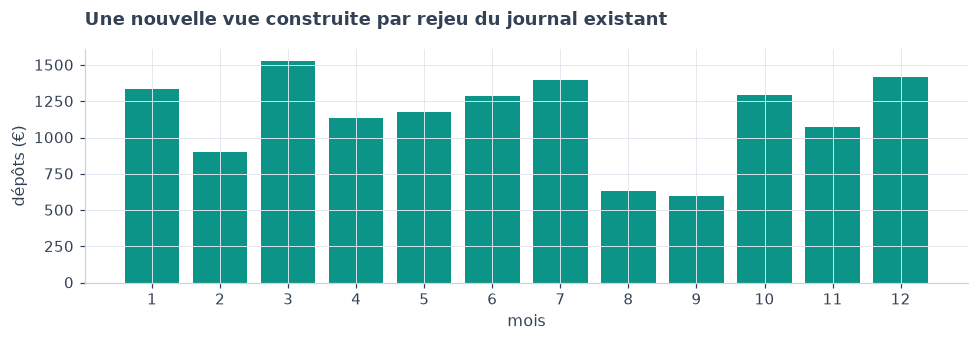

In [3]:
es = st.EventStore()
mois = []
for m in range(1, 13):
    for _ in range(int(rng.integers(3, 9))):
        es.append("compte-42", [("Depose", {"montant": int(rng.integers(20, 300)), "mois": m})])
        if rng.random() < 0.6:
            es.append("compte-42", [("Retire", {"montant": int(rng.integers(10, 100)), "mois": m})])
def releve(etat, e):
    etat = dict(etat or {})
    if e.type == "Depose":
        etat[e.data["mois"]] = etat.get(e.data["mois"], 0) + e.data["montant"]
    return etat
r = st.replay(es.read("compte-42"), releve)
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.bar(list(r.keys()), list(r.values()), color=TEAL)
ax.set_xlabel("mois"); ax.set_ylabel("dépôts (€)")
ax.set_title("Une nouvelle vue construite par rejeu du journal existant")
ax.set_xticks(range(1, 13))
plt.tight_layout(); plt.show()

> **À retenir.** En event sourcing, une commande est validée contre l'état du flux puis
> ajoutée avec la version lue : le contrôle optimiste empêche l'écriture biaisée dans un
> flux. Les instantanés bornent le rejeu, et toute nouvelle vue se construit en rejouant.

## Exercice 11.8 : fenêtres à la main

**Énoncé.** Un utilisateur produit des événements aux instants (en secondes)
3, 7, 12, 14, 31, 33, 34, 52, 58, 61, 95, 99.

1. Compter les événements par fenêtre fixe de 20 s (origine 0).
2. Même question avec des fenêtres par sauts de 20 s et de saut 10 s. Combien de fois
   chaque événement est-il compté ?
3. Fenêtre glissante de 20 s : pour chaque événement, nombre d'événements dans
   $]t - 20, t]$. Quel est le maximum ? Une fenêtre fixe aurait-elle détecté une rafale de
   4 événements en 20 s placée à cheval sur une frontière ?
4. Sessions avec une inactivité de 10 s : combien de sessions, de quelles durées ?
5. Vérifier avec les fonctions du module.

**Rappels.** Types de fenêtres (cours 6, section 4, section *Types of windows*).

**Solution.**

*1.* $[0,20)$ : 3, 7, 12, 14, soit **4** ; $[20,40)$ : 31, 33, 34, soit **3** ;
$[40,60)$ : 52, 58, soit **2** ; $[60,80)$ : 61, soit **1** ; $[80,100)$ : 95, 99, soit
**2**. Total 12.

*2.* Fenêtres $[-10,10)$ : 2 ; $[0,20)$ : 4 ; $[10,30)$ : 2 ; $[20,40)$ : 3 ;
$[30,50)$ : 3 ; $[40,60)$ : 2 ; $[50,70)$ : 3 ; $[60,80)$ : 1 ; $[70,90)$ : 0 ;
$[80,100)$ : 2 ; $[90,110)$ : 2. Chaque événement est compté
$20/10 = 2$ fois (total 24).

*3.* Comptes : 1, 2, 3, 4, 3, 3, 3, 3, 2, 3, 1, 2. Pour 34, la fenêtre $]14, 34]$
exclut 14 ; pour 61, $]41, 61]$ contient 52, 58 et 61. Le maximum est **4** (à
$t = 14$). Une rafale de 4 événements à cheval sur une frontière (par exemple 17, 19, 21,
23) serait coupée en 2 + 2 par des fenêtres fixes de 20 s et passerait inaperçue sous un
seuil de 4 : la fenêtre glissante n'a pas de frontière arbitraire.

*4.* Écarts : 4, 5, 2, **17**, 2, 1, **18**, 6, 3, **34**, 4. Les écarts supérieurs à
10 s coupent les sessions : $[3, 14]$ (4 événements, 11 s), $[31, 34]$ (3, 3 s),
$[52, 61]$ (3, 9 s), $[95, 99]$ (2, 4 s). **Quatre sessions.**

In [4]:
ts = [3, 7, 12, 14, 31, 33, 34, 52, 58, 61, 95, 99]
fixes = st.tumbling_counts(ts, 20)
sauts = st.hopping_counts(ts, 20, 10)
gliss = st.sliding_counts(ts, 20)
sess = st.sessionize([("u", t) for t in ts], gap=10)
assert fixes == {0: 4, 20: 3, 40: 2, 60: 1, 80: 2}
assert sauts == {-10: 2, 0: 4, 10: 2, 20: 3, 30: 3, 40: 2, 50: 3, 60: 1, 80: 2, 90: 2}   # [70, 90) vide
assert list(gliss) == [1, 2, 3, 4, 3, 3, 3, 3, 2, 3, 1, 2]
assert [(a, b, n) for _, a, b, n in sess] == [(3, 14, 4), (31, 34, 3), (52, 61, 3), (95, 99, 2)]
rafale = [17, 19, 21, 23]
print("toutes les réponses sont vérifiées ;",
      "rafale :", st.tumbling_counts(rafale, 20), "en fixes contre max", st.sliding_counts(rafale, 20).max(), "en glissante")

toutes les réponses sont vérifiées ; rafale : {0.0: 2, 20.0: 2} en fixes contre max 4 en glissante


> **À retenir.** Fixe : une fenêtre par événement ; par sauts : longueur/saut fenêtres
> par événement ; glissante : pas de frontière, idéale pour détecter des rafales ; session :
> des durées qui suivent l'activité.

## Exercice 11.9 : choisir la marge d'un filigrane

**Énoncé.** Les délais entre la création d'un événement et son arrivée suivent une loi
log-normale de médiane 0,4 s et de paramètre $\sigma = 1$. On compte les événements par
fenêtres fixes de 10 s, avec un filigrane « plus grand temps vu moins $L$ ».

1. Quelle marge $L$ garantit que moins de 0,1 % des événements ont un délai supérieur à
   $L$ ? Pourquoi est-ce une **borne supérieure** de la fraction de retardataires
   écartés ?
2. Vérifier par simulation (20 000 événements par heure) la fraction écartée pour
   plusieurs valeurs de $L$, et la comparer à la borne.
3. On ajoute 1 % d'appareils hors ligne dont les événements arrivent avec des heures de
   retard. Que proposer ?

**Rappels.** Filigranes, retardataires, corrections (cours 6, section 2, section
*Knowing when you're ready*).

**Solution.**

*1.* $P(D > L) = 1 - \Phi\left(\frac{\ln L - \ln 0{,}4}{\sigma}\right) \le 10^{-3}$, soit
$\ln L \ge \ln 0{,}4 + z_{0{,}999}\,\sigma$ avec $z_{0{,}999} \approx 3{,}09$ :
$L \ge 0{,}4\,e^{3{,}09} \approx 8{,}8$ s. C'est une borne supérieure, car un événement de
délai $D > L$ n'est écarté que si sa fenêtre est déjà close à son arrivée : il faut qu'un
événement d'horodatage postérieur à « fin de sa fenêtre + $L$ » soit arrivé avant lui.
Un événement créé au début de sa fenêtre dispose en plus du temps restant jusqu'à la fin
de la fenêtre : la fraction réellement écartée est plus faible que la borne.

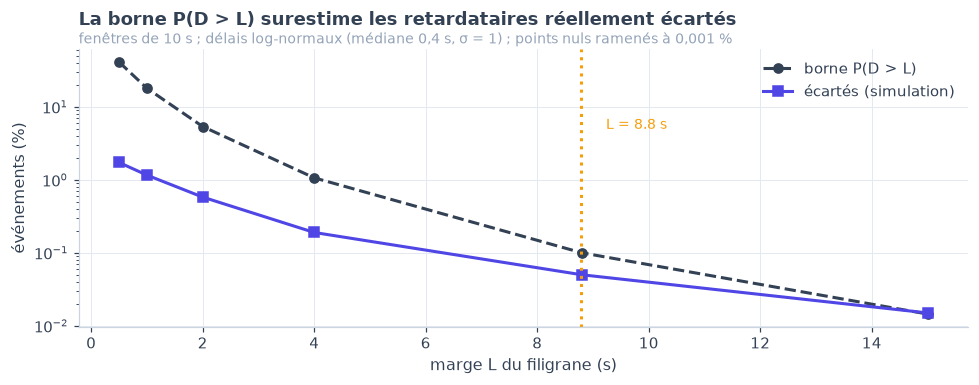

,"écartés (simulé, %)",borne P(D > L) (%)
L (s),,
0.5,1.730,41.171
1.0,1.160,17.976
2.0,0.580,5.376
4.0,0.190,1.065
8.8,0.050,0.100
15.0,0.015,0.015


In [5]:
L_borne = 0.4 * math.exp(Z.inv_cdf(0.999) * 1.0)
n = 20_000
et = np.sort(rng.uniform(0, 3600, n))
dl = rng.lognormal(math.log(0.4), 1.0, n)
rows = []
for L in [0.5, 1, 2, 4, L_borne, 15]:
    wc = st.WatermarkCounter(10, lateness=L).run(et, et + dl)
    rows.append({"L (s)": round(L, 1), "écartés (simulé, %)": wc.dropped / n * 100,
                 "borne P(D > L) (%)": (1 - Z.cdf((math.log(L) - math.log(0.4)) / 1.0)) * 100})
F = pd.DataFrame(rows).set_index("L (s)")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(F.index, F["borne P(D > L) (%)"], "o--", color=SLATE, label="borne P(D > L)")
ax.plot(F.index, F["écartés (simulé, %)"].clip(lower=1e-3), "s-", color=INDIGO, label="écartés (simulation)")
ax.axvline(L_borne, color=AMBER, ls=":")
ax.text(L_borne * 1.05, 5, f"L = {L_borne:.1f} s", color=AMBER, fontsize=9)
ax.set_yscale("log")
ax.set_xlabel("marge L du filigrane (s)"); ax.set_ylabel("événements (%)")
ax.set_title("La borne P(D > L) surestime les retardataires réellement écartés")
subtitle(ax, "fenêtres de 10 s ; délais log-normaux (médiane 0,4 s, σ = 1) ; points nuls ramenés à 0,001 %")
ax.legend()
plt.tight_layout(); plt.show()
F.round(4)

*2.* La simulation confirme : la fraction écartée ne dépasse jamais la borne, et lui est souvent
très inférieure, parce que la plupart des événements disposent d'un délai de
grâce supplémentaire (le reste de leur fenêtre).

*3.* Attendre des heures pour 1 % des événements retarderait tous les résultats et
garderait des milliers de fenêtres ouvertes. On choisit plutôt une marge courte pour le
résultat « rapide », et l'on traite les retardataires autrement : publication de
**corrections** pour les fenêtres concernées (si les consommateurs savent les appliquer),
ou envoi des retardataires dans un flux à part, recalculé par lots (et comptés, pour
alerter si leur proportion grimpe). Les trois horodatages du cours 6 permettent en outre
de les dater correctement.

> **À retenir.** $P(D > L)$ borne par excès la fraction écartée ; on choisit $L$ sur le
> quantile des délais ordinaires et l'on traite les retards extrêmes par corrections ou
> en différé.

## Exercice 11.10 : jointure recherches-clics, fenêtre et taille de l'état

**Énoncé.** Un moteur reçoit 2 000 recherches par seconde. 30 % donnent un clic, après un
délai log-normal de médiane 10 s et $\sigma = 1{,}5$. La jointure flux-flux garde en
mémoire les recherches pendant au plus $W$ (300 octets chacune).

1. Quelle fenêtre $W$ capte 99 % des clics ?
2. Avec cette fenêtre, combien de recherches sont en mémoire en moyenne ? Quelle
   mémoire ? (Loi de Little : nombre moyen = débit × durée moyenne de séjour.)
3. Quelle erreur sur le taux de clic fait-on avec $W = 60$ s ?
4. Vérifier par simulation à échelle réduite (20 recherches par seconde).

**Rappels.** Jointure fenêtrée et taille de l'état (cours 7, section 1, section
*Stream-stream join (window join)*) ; loi de Little (chapitre 1).

**Solution.**

*1.* $P(D \le W) = \Phi\left(\frac{\ln W - \ln 10}{1{,}5}\right) = 0{,}99$, soit
$W = 10\,e^{1{,}5 \times 2{,}326} \approx 328$ s, environ 5 minutes et demie.

*2.* Une recherche non cliquée (70 %) reste $W$ ; une recherche cliquée reste
$\min(D, W)$. Durée moyenne de séjour $S = 0{,}7\,W + 0{,}3\,E[\min(D, W)]$ ; on calcule
$E[\min(D, W)]$ numériquement. Nombre moyen en mémoire $N = 2\,000 \times S$.

*3.* Avec $W = 60$ s, on ne capte que $\Phi((\ln 60 - \ln 10)/1{,}5)$ des clics : le taux
de clic mesuré vaut $0{,}3 \times$ cette fraction.

In [6]:
def e_min(med, sigma, W, n=400_000, seed=1):
    d = np.random.default_rng(seed).lognormal(math.log(med), sigma, n)
    return np.minimum(d, W).mean()
W99 = 10 * math.exp(1.5 * Z.inv_cdf(0.99))
S = 0.7 * W99 + 0.3 * e_min(10, 1.5, W99)
N = 2000 * S
capt60 = Z.cdf((math.log(60) - math.log(10)) / 1.5)
print(f"W99 = {W99:.0f} s ; séjour moyen S = {S:.0f} s ; recherches en mémoire N = {N:,.0f} ; mémoire ≈ {N * 300 / 1e6:.0f} Mo".replace(",", " "))
print(f"W = 60 s : {capt60:.1%} des clics captés, taux de clic mesuré {0.3 * capt60:.1%} au lieu de 30 %")

# simulation à 20 recherches/s pendant 2 heures
lam, duree = 20, 7200
t_s = np.sort(rng.uniform(0, duree, lam * duree))
clic = rng.random(t_s.size) < 0.3
evts = [("search", i, t) for i, t in enumerate(t_s)]
evts += [("click", i, t + rng.lognormal(math.log(10), 1.5)) for i, t in enumerate(t_s) if clic[i]]
evts.sort(key=lambda e: e[2])
rows = []
for W in [60, W99]:
    j = st.SearchClickJoin(W)
    for kind, sid, t in evts:
        j.process(kind, sid, t)
    j.flush()
    oui = sum(o[0] == "clicked" for o in j.out)
    regime = np.array(j.state_size[len(j.state_size) // 3:])        # hors montée en charge
    rows.append({"W (s)": round(W), "taux de clic mesuré": oui / t_s.size,
                 "état moyen simulé": regime.mean(),
                 "Little : λ·S (à 20 rech./s)": lam * (0.7 * W + 0.3 * e_min(10, 1.5, W))})
pd.DataFrame(rows).set_index("W (s)").round(3)

W99 = 328 s ; séjour moyen S = 238 s ; recherches en mémoire N = 475 332 ; mémoire ≈ 143 Mo
W = 60 s : 88.4% des clics captés, taux de clic mesuré 26.5% au lieu de 30 %


,taux de clic mesuré,état moyen simulé,Little : λ·S (à 20 rech./s)
W (s),,,
60,0.266,989.091,951.564
328,0.298,4756.620,4753.324


*4.* La simulation retrouve le taux de clic attendu pour chaque fenêtre et un état moyen
proche de $\lambda S$ (l'état simulé compte aussi quelques clics en attente de leur
recherche, ici aucun puisque les événements arrivent dans l'ordre). À 2 000 recherches
par seconde, l'état de la jointure tient en 150 Mo environ : il est
raisonnable de le garder en mémoire, partitionné par identifiant de session, et répliqué
(cours 7, section 8).

> **À retenir.** La fenêtre d'une jointure flux-flux se choisit sur un quantile du délai
> entre les deux événements ; l'état vaut, par la loi de Little, débit × durée moyenne de
> séjour.